In [1]:
import catkit2
from catkit2 import TestbedProxy
import hcipy
from hcipy import *
from astropy.io import fits

In [2]:
testbed = TestbedProxy("localhost",5465)

In [3]:
boston_rows = 32
boston_cols = 32
boston_grid = [boston_rows, boston_cols]

alpao_rows = 11
alpao_cols = 11
alpao_grid = [alpao_rows, alpao_cols]

flat_boston = np.zeros(boston_grid)
flat_alpao = np.zeros(alpao_grid)

testbed.boston_dm.apply_shape('poke',flat_boston)
testbed.boston_dm.apply_shape('aberration',flat_boston)
testbed.boston_dm.apply_shape('correction',flat_boston)

testbed.alpao_dm.apply_shape('correction',flat_alpao)
testbed.alpao_dm.apply_shape('poke',flat_alpao)

In [4]:
def gradient_y(array_len, start, end):
    values = (end-start)/array_len
    x = np.linspace(start,end,array_len)
    y = values * x
    
    act = np.zeros((array_len, array_len))
    
    for i in range(array_len):
        act[i,:] = y[i]
        
    return(act)

In [5]:
def gradient_x(array_len, start, end):
    values = (end-start)/array_len
    x = np.linspace(start,end,array_len)
    y = values * x
    
    act = np.zeros((array_len, array_len))
    
    for i in range(array_len):
        act[:,i] = y[i]
        
    return(act)

In [6]:
flat_tilt = -gradient_y(11,-33,33)-gradient_x(11,-10,10)
testbed.alpao_dm.apply_shape('correction', flat_tilt)

In [7]:
import scipy.optimize
import hcipy
import time

num_modes = 2 + 3 + 4 + 5 + 6 + 7 + 8 + 9 + 10
actuator_grid = hcipy.make_pupil_grid(11, 1)
zernike_modes = hcipy.make_zernike_basis(num_modes, 1, actuator_grid, 2)

k = 17

start_time=time.time()
print(start_time)

def f(x):
    testbed.alpao_dm.apply_shape('poke', zernike_modes.linear_combination(x).shaped)
    
    img = np.sum(list(testbed.pywfs_camera.take_raw_exposures(2)), axis=0) / 2
    img = np.roll(img, (0, -5), axis=(1, 0))[k:-k, k:-k]
    n = img.shape[0]
                  
    a = img[:n // 2, :n // 2]
    b = img[n // 2:, :n // 2]
    c = img[:n // 2, n // 2:]
    d = img[n // 2:, n // 2:]
    
    grad_x = a - b + c - d
    grad_y = a + b - c - d
    
    res = (np.abs(grad_x)**2 + np.abs(grad_y)**2).sum()
    
    if time.time()-start_time>100:
        raise TimeoutError("Timelimit exeeded")
    #print(res, x)
    
    return res

x0 = np.zeros(num_modes)

initial_simplex = [
    x0, *(np.eye(num_modes) * 3 + x0[np.newaxis,:])
]

options = {'initial_simplex': initial_simplex, 'xatol': 0.5}
scipy.optimize.minimize(f, initial_simplex[0], method='Nelder-Mead', options=options)

1793914927.4535377


KeyboardInterrupt: 

In [65]:
actuator_grid = hcipy.make_pupil_grid(11,1)
Z = hcipy.zernike(2,0,D=1,grid=actuator_grid)
amplitude = 0 #abberation strength 
testbed.alpao_dm.apply_shape("aberration",(amplitude*Z).shaped)

In [67]:
actuator_grid = hcipy.make_pupil_grid(11,1)
Z = hcipy.zernike(2,0,D=1,grid=actuator_grid)
amplitude = 0 #abberation strength 
testbed.alpao_dm.apply_shape("aberration",(amplitude*Z).shaped)

<class 'generator'>
<class 'list'>


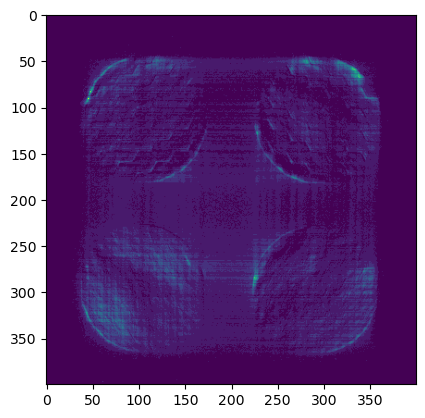

In [11]:
N = 1

image_ref = testbed.pywfs_camera.take_raw_exposures(N)
print(type(image_ref))
image_ref=list(image_ref)
print(type(image_ref))
image_ref=image_ref[0]
plt.imshow(image_ref);

(array([[400.,   0.,   0., ...,   0.,   0.,   0.],
        [400.,   0.,   0., ...,   0.,   0.,   0.],
        [400.,   0.,   0., ...,   0.,   0.,   0.],
        ...,
        [400.,   0.,   0., ...,   0.,   0.,   0.],
        [400.,   0.,   0., ...,   0.,   0.,   0.],
        [400.,   0.,   0., ...,   0.,   0.,   0.]]),
 array([ 7.        ,  8.39999962,  9.80000019, 11.19999981, 12.60000038,
        14.        , 15.39999962, 16.79999924, 18.20000076, 19.60000038,
        21.        ]),
 <a list of 400 BarContainer objects>)

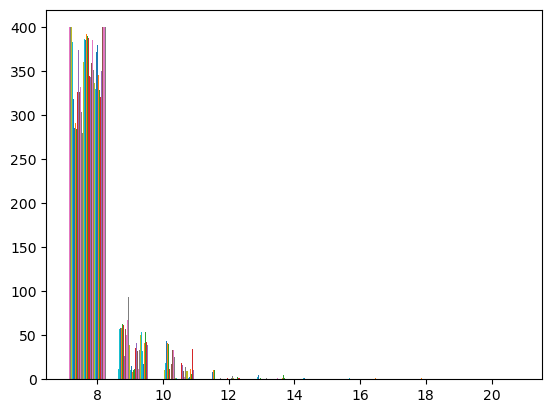

In [15]:
plt.hist(image_ref)

<class 'generator'>
<class 'list'>


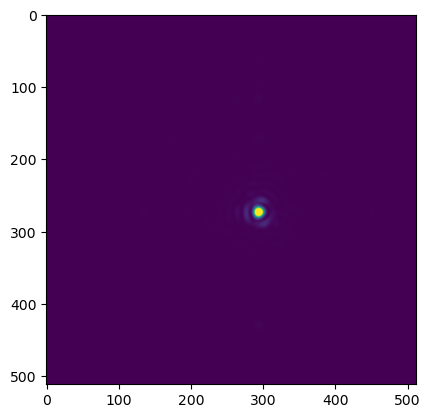

In [12]:
N = 1

psf_ref = testbed.vortex_camera.take_raw_exposures(N)
print(type(psf_ref))
psf_ref=list(psf_ref)
print(type(psf_ref))
psf_ref=psf_ref[0]
plt.imshow(psf_ref);

In [20]:
psf_directory="/home/lab/rnobileo/june25/"
for i in range(300):
    psf_ref = testbed.vortex_camera.take_raw_exposures(N)
    psf_ref=list(psf_ref)
    psf_ref=psf_ref[0]
    fits.writeto(f"{psf_directory}psf_{i}.fits",psf_ref,overwrite=True)

In [21]:
wsf_directory="/home/lab/rnobileo/june25/"
for i in range(300):
    wsf_ref = testbed.pywfs_camera.take_raw_exposures(N)
    wsf_ref=list(psf_ref)
    wsf_ref=psf_ref[0]
    fits.writeto(f"{wsf_directory}wfs_{i}.fits",wsf_ref,overwrite=True)

In [22]:
psf_directory="/home/lab/rnobileo/june25/" #laser off
for i in range(10):
    psf_ref = testbed.vortex_camera.take_raw_exposures(N)
    psf_ref=list(psf_ref)
    psf_ref=psf_ref[0]
    fits.writeto(f"{psf_directory}dark_{i}.fits",psf_ref,overwrite=True)